In [33]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix,ConfusionMatrixDisplay, classification_report

In [2]:
IMAGES ='./images/'

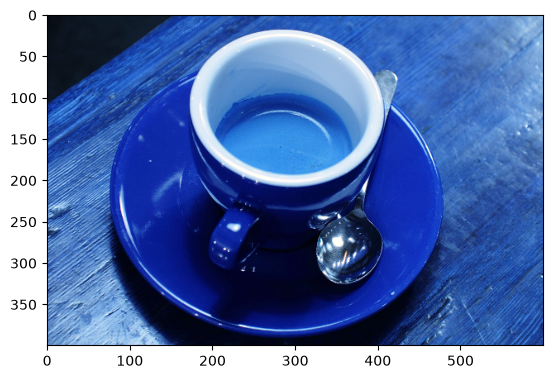

In [3]:
image = cv2.imread(IMAGES + "coffee.png")
plt.imshow(image) 
plt.show()

In [4]:
print("Type:", type(image))

Type: <class 'numpy.ndarray'>


In [5]:
print("Shape:", image.shape)

Shape: (400, 600, 3)


In [6]:
print("Data type:", image.dtype)

Data type: uint8


In [7]:
print("Smallest value:", image.min())
print("Largest value:", image.max()) 

Smallest value: 0
Largest value: 255


In [8]:
height, width, channels = image.shape
print("Height:", height, "pixels")
print("Width:", width, "pixels")
print("Channels:", channels)

Height: 400 pixels
Width: 600 pixels
Channels: 3


In [ ]:
# digit recognition

In [9]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

In [10]:
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)


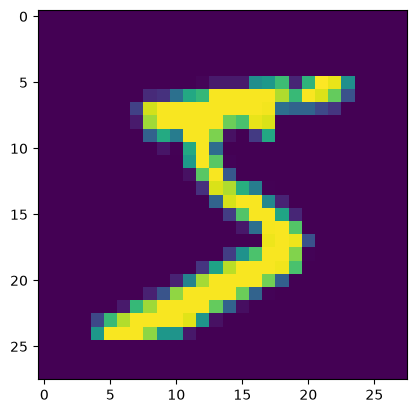

In [11]:
plt.imshow(x_train[0])

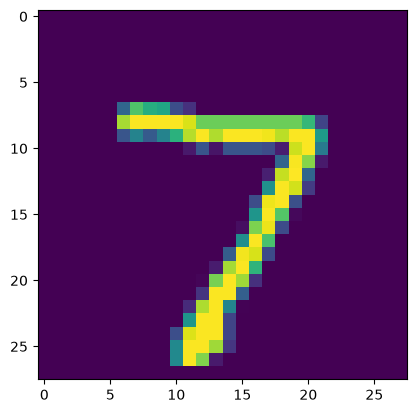

In [12]:
plt.imshow(x_test[0])

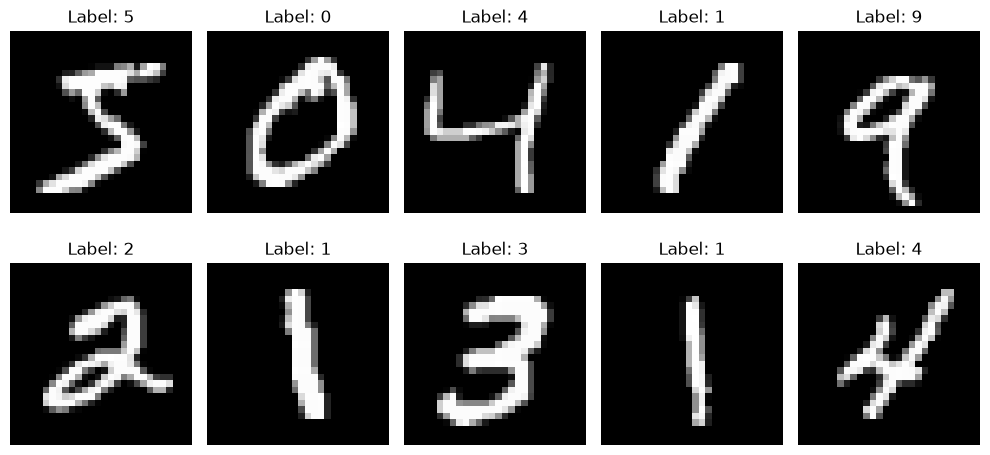

In [13]:
# Now let's actually SEE the first 10 training images with their labels
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [14]:
# normalize pixel values from [0, 255] to [0.0, 1.0]

x_train_norm = x_train/255.0
x_test_norm = x_test/255.0

In [15]:
x_test_norm[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [16]:
x_train_norm[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [17]:
#  add the channel dimension so shape goes from (28, 28) to (28, 28, 1)

x_train_final = x_train_norm.reshape(-1, 28, 28, 1)
x_test_final = x_test_norm.reshape(-1, 28, 28, 1)


print("Shape before reshape:", x_train_norm.shape)
print("Shape after reshape:", x_train_final.shape)

Shape before reshape: (60000, 28, 28)
Shape after reshape: (60000, 28, 28, 1)


In [22]:
model = keras.Sequential([
    keras.layers.Input(shape=(28,28,1)),

    # first magnifying glass pass:8 filters, each looking at a 3x3 patch at a time
    keras.layers.Conv2D(8, kernel_size=(3,3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2)), #shrink the image , keep the strongest signals

    # Second pass: 16 filters, now looking for slightly bigger/combined patterns
    keras.layers.Conv2D(16, kernel_size=(3, 3), activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),
    
    keras.layers.Flatten(), # unroll the grid into a flat list
    keras.layers.Dense(32, activation="relu"), # combine the clues
    keras.layers.Dense(10, activation="softmax"), # final decision: a probability for each of the 10 digits

    ])

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)                    │ (None, 26, 26, 8)           │              80 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 13, 13, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 11, 11, 16)          │           1,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 5, 5, 16)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 400)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │          12,832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             330 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,410 (56.29 KB)

 Trainable params: 14,410 (56.29 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [26]:
history=model.fit(
    x_train_final, y_train,
    epochs=5,
    validation_split=0.1,
    batch_size=64
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8977 - loss: 0.3337 - val_accuracy: 0.9665 - val_loss: 0.1120
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9684 - loss: 0.0991 - val_accuracy: 0.9772 - val_loss: 0.0790
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9764 - loss: 0.0764 - val_accuracy: 0.9808 - val_loss: 0.0711
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9800 - loss: 0.0640 - val_accuracy: 0.9840 - val_loss: 0.0617
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9833 - loss: 0.0539 - val_accuracy: 0.9825 - val_loss: 0.0623


In [27]:
test_loss, test_accuracy = model.evaluate(x_test_final, y_test)
print(f"\nFinal test accuracy: {test_accuracy:.4f} (test loss: {test_loss:.4f})")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9829 - loss: 0.0531

Final test accuracy: 0.9829 (test loss: 0.0531)


In [28]:
# Predict probabilities for the first 10 test images
probabilities = model.predict(x_test_final[:10])
print("Probabilities for the very first test image:\n", np.round(probabilities[0], 3))
predicted_labels = np.argmax(probabilities, axis=1)
print("\nPredicted labels:", predicted_labels)
print("True labels: ", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step
Probabilities for the very first test image:
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]

Predicted labels: [7 2 1 0 4 1 4 9 5 9]
True labels:  [7 2 1 0 4 1 4 9 5 9]


In [30]:
y_pred = model.predict(x_test_final)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [31]:
np.argmax([100,2,30])

np.int64(0)

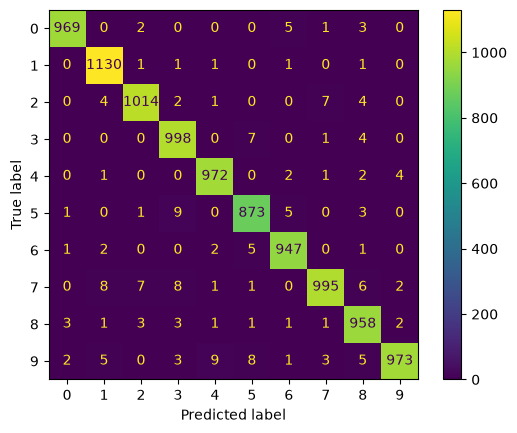

In [34]:
cm = confusion_matrix(y_test, np.argmax(y_pred, axis=1),labels=[0,1,2,3,4,5,6,7,8,9])
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=[0,1,2,3,4,5,6,7,8,9]).plot()

In [36]:
accuracy_score(y_test,np.argmax(y_pred, axis=1))

0.9829

In [37]:
pred_data = np.array(x_test[0]).reshape(-1,28,28,1)
model.predict(pred_data)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step


array([[0., 0., 0., 0., 0., 0., 0., 1., 0., 0.]], dtype=float32)